In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import california_housing



In [ ]:
# Load dataset
(x_train, y_train), (x_test, y_test) = california_housing.load_data()

# Keras only gives you NumPy arrays so here we convert to DataFrame for exploration
columns = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude"
]
df_train = pd.DataFrame(x_train, columns=columns)
df_train["target"] = y_train

# Explore
print(df_train.shape)
print(df_train.head(3))
print(df_train.describe())


(16512, 9)
       MedInc   HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0 -118.269997  34.090000      52.0     2327.0       555.0    1048.0     491.0   
1 -118.360001  33.959999      21.0     1802.0       556.0    1286.0     557.0   
2 -122.389999  37.759998      52.0     1877.0       427.0     712.0     398.0   

   Longitude    target  
0     3.7847  252300.0  
1     2.7284  146900.0  
2     3.9722  290900.0  
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  16512.000000  16512.000000  16512.000000  16512.000000  16512.000000   
mean    -119.562263     35.625362     28.654131   2644.717285    539.574280   
std        2.001162      2.129766     12.597428   2210.142822    426.147491   
min     -124.349998     32.549999      1.000000      2.000000      1.000000   
25%     -121.790001     33.930000     18.000000   1451.000000    295.000000   
50%     -118.489998     34.250000     29.000000   2133.500000    436.000000   
75%     -11

In [ ]:
#The California Housing dataset is a supervised regression dataset containing
#demographic, geographic and housing-related variables.
#The dataset is divided into training and testing subsets
#Initial exploration shows that the predictors have different numerical ranges and distributions.
#Therefore, preprocessing, particularly feature
#standardization, is required before training the ANN.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# here we are to fit the training data
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Scaled training data:")
print(x_train_scaled[:5])

Scaled training data:
[[ 0.6457759  -0.7209302   1.8532751  -0.14375815  0.03619913 -0.3331862
  -0.02698459 -0.04505231]
 [ 0.60079885 -0.78197217 -0.60761106 -0.38130605  0.03854581 -0.12736216
   0.14330861 -0.6016902 ]
 [-1.4130851   1.0023171   1.8532751  -0.34737062 -0.2641757  -0.62376136
  -0.2669432   0.05375447]
 [ 0.8056872  -0.8007546  -1.4014454   0.2182196   0.39054757  0.13899839
   0.496796    0.24894394]
 [-1.4780477   1.077445   -0.36946082 -1.00617    -1.11602    -1.0985404
  -1.1003478   5.64548   ]]


In [ ]:
#here we want to create a validation dataset
from sklearn.model_selection import train_test_split


x_train_final, x_val, y_train_final, y_val = train_test_split(
    x_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Training:", x_train_final.shape)
print("Validation:", x_val.shape)
print("Test:", x_test_scaled.shape)

Training: (13209, 8)
Validation: (3303, 8)
Test: (4128, 8)


In [ ]:
'''To ensure that variables with larger numerical ranges do not dominate the
learning process. The scaler was fitted only on the
training data and then applied to the validation and test datasets.
This prevents data leakage. The original training dataset was further divided
into training and validation subsets, while the independent test dataset was
retained for final evaluation of the model on unseen data.'''

In [ ]:
#this is a regression output will contain 1 neuron"

model = keras.Sequential([
    layers.Input(shape=(x_train_final.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="linear")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [ ]:
#in this step we perform model training:
history = model.fit(
    x_train_final,
    y_train_final,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 54207565824.0000 - mae: 202433.5938 - val_loss: 45707776000.0000 - val_mae: 182599.9844
Epoch 2/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 25739935744.0000 - mae: 123511.3594 - val_loss: 12197220352.0000 - val_mae: 81041.6406
Epoch 3/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 10900665344.0000 - mae: 75915.0469 - val_loss: 9567129600.0000 - val_mae: 71224.6641
Epoch 4/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 8952505344.0000 - mae: 68408.5469 - val_loss: 8310843904.0000 - val_mae: 65871.9844
Epoch 5/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7725887488.0000 - mae: 63261.4688 - val_loss: 7360019968.0000 - val_mae: 62031.4570
Epoch 6/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6812466176.0000 - mae: 59669.9062 - val_loss: 6648500224.0000 - val_mae: 58881.7070
Epoch 7/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6106485760.0000 - mae: 56682.9688 - val_loss: 6110525440.0000

In [ ]:
'''during training, the training loss generally decreases as the ANN learns the relationship
 between the input variables and median house value. The validation loss also
 decrease initially, indicating that the model is learning patterns that generalise to
 previously unseen validation observations. so theres no overfitting.'''

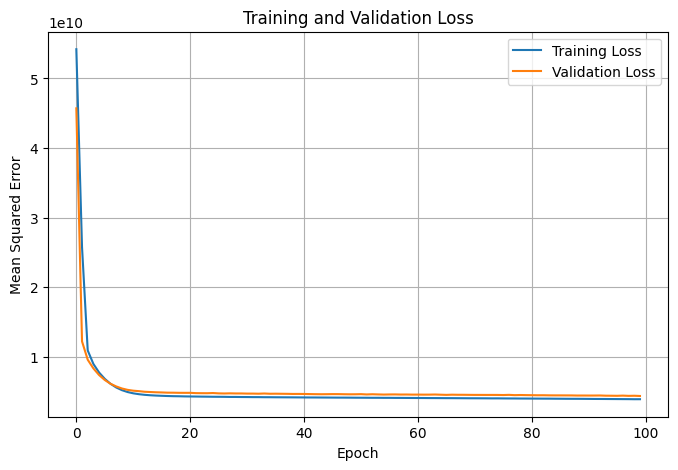

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_mae = model.evaluate(
    x_test_scaled,
    y_test,
    verbose=0
)

print("Test MSE:", test_loss)
print("Test MAE:", test_mae)

Test MSE: 4220809472.0
Test MAE: 45544.515625


In [ ]:
#here we add rmse because it will be compare to MAE/MSE
test_rmse = np.sqrt(test_loss)
print("Test RMSE:", test_rmse)

Test RMSE: 64967.75717230817


In [ ]:
'''cONCLUSION: The trained ANN was evaluated using tto measure its
performance on unseen observations. The MAE represents the average absolute
difference between the predicted and actual median house values, while the
RMSE gives greater weight to larger prediction errors'''